In [2]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import os
DATOS="../../Practicas_IA_Explicable_practicantes/german_credit.csv"
print("¿El archivo existe?:", os.path.exists(DATOS))
datos_df = pd.read_csv(DATOS)
X = datos_df.drop(columns=["class"]).copy()
y_texto = datos_df["class"].copy()
Y=(y_texto=="bad").astype(int)
tmp = X.copy()
tmp["impago"] = Y.values

¿El archivo existe?: True


In [3]:
print(pd.crosstab(X["housing"], Y, normalize="index") * 100)
print(pd.crosstab(X["checking_status"], Y, normalize="index") * 100)
print(pd.crosstab(X["credit_history"], Y, normalize="index") * 100)
print(pd.crosstab(X["purpose"], Y, normalize="index") * 100)
print(pd.crosstab(X["employment"], Y, normalize="index") * 100)
print(pd.crosstab(X["savings_status"], Y, normalize="index") * 100)
print(pd.crosstab(X["personal_status"], Y, normalize="index") * 100)
print(pd.crosstab(X["other_parties"], Y, normalize="index") * 100)
print(pd.crosstab(X["property_magnitude"], Y, normalize="index") * 100)
print(pd.crosstab(X["other_payment_plans"], Y, normalize="index") * 100)
print(pd.crosstab(X["existing_credits"], Y, normalize="index") * 100)
print(pd.crosstab(X["job"], Y, normalize="index") * 100)
print(pd.crosstab(X["own_telephone"], Y, normalize="index") * 100)
print(pd.crosstab(X["foreign_worker"], Y, normalize="index") * 100)

class             0          1
housing                       
for free  59.259259  40.740741
own       73.913043  26.086957
rent      60.893855  39.106145
class                    0          1
checking_status                      
0<=X<200         60.966543  39.033457
<0               50.729927  49.270073
>=200            77.777778  22.222222
no checking      88.324873  11.675127
class                                   0          1
credit_history                                      
all paid                        42.857143  57.142857
critical/other existing credit  82.935154  17.064846
delayed previously              68.181818  31.818182
existing paid                   68.113208  31.886792
no credits/all paid             37.500000  62.500000
class                        0          1
purpose                                  
business             64.948454  35.051546
domestic appliance   66.666667  33.333333
education            56.000000  44.000000
furniture/equipment  67.955801  32.0

--- TASA DE DEFAULT POR RANGOS DE EDAD ---
impago                           0          1
rango_edad                                   
<25 (Jóvenes)            57.894737  42.105263
25-34 (Adultos Jóvenes)  70.351759  29.648241
35-49 (Madurez)          76.254181  23.745819
50-64 (Pre-retiro)       72.631579  27.368421
>=65 (Retiro)            72.222222  27.777778


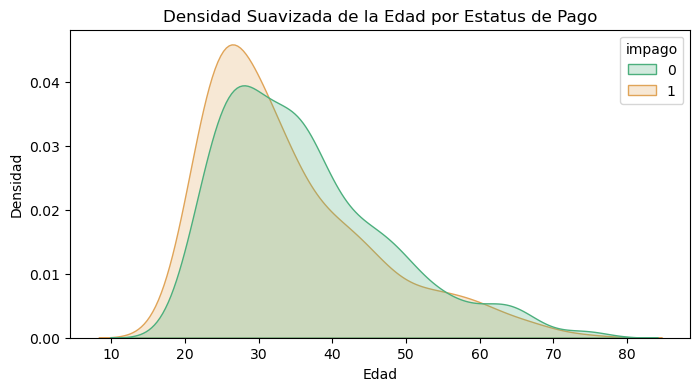

In [4]:
cortes_edad = [0, 25, 35, 50, 65, 100]
etiquetas_edad = ['<25 (Jóvenes)', '25-34 (Adultos Jóvenes)', '35-49 (Madurez)', '50-64 (Pre-retiro)', '>=65 (Retiro)']

tmp['rango_edad'] = pd.cut(tmp['age'], bins=cortes_edad, labels=etiquetas_edad)

print("--- TASA DE DEFAULT POR RANGOS DE EDAD ---")
print(pd.crosstab(tmp['rango_edad'], tmp['impago'], normalize='index') * 100)

plt.figure(figsize=(8, 4))
sb.kdeplot(data=tmp, x="age", hue="impago", fill=True, common_norm=False, palette=["#4CAF7D", "#E0A458"])
plt.title("Densidad Suavizada de la Edad por Estatus de Pago")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.show()

In [5]:
interaccion_perfiles = tmp.groupby(['housing', 'employment'])['impago'].mean() * 100

print("--- ANÁLISIS DE INTERACCIÓN: VIVIENDA + TIEMPO DE EMPLEO ---")
print(interaccion_perfiles.round(2))

--- ANÁLISIS DE INTERACCIÓN: VIVIENDA + TIEMPO DE EMPLEO ---
housing   employment
for free  1<=X<4        46.15
          4<=X<7        54.55
          <1            33.33
          >=7           42.00
          unemployed    20.00
own       1<=X<4        26.59
          4<=X<7        20.61
          <1            36.13
          >=7           18.60
          unemployed    43.59
rent      1<=X<4        40.98
          4<=X<7        18.75
          <1            53.19
          >=7           35.48
          unemployed    37.50
Name: impago, dtype: float64


--- ESTADÍSTICAS CUANTITATIVAS SEGMENTADAS POR IMPAGO ---
impago               0        1
Monto_Media    2985.46  3938.13
Monto_Mediana  2244.00  2574.50
Monto_DesvEst  2401.47  3535.82
Monto_P75      3634.75  5141.50
Monto_P90      6318.70  8983.60
Plazo_Media      19.21    24.86
Plazo_Mediana    18.00    24.00
Plazo_DesvEst    11.08    13.28
Plazo_P75        24.00    36.00
Plazo_P90        36.00    48.00


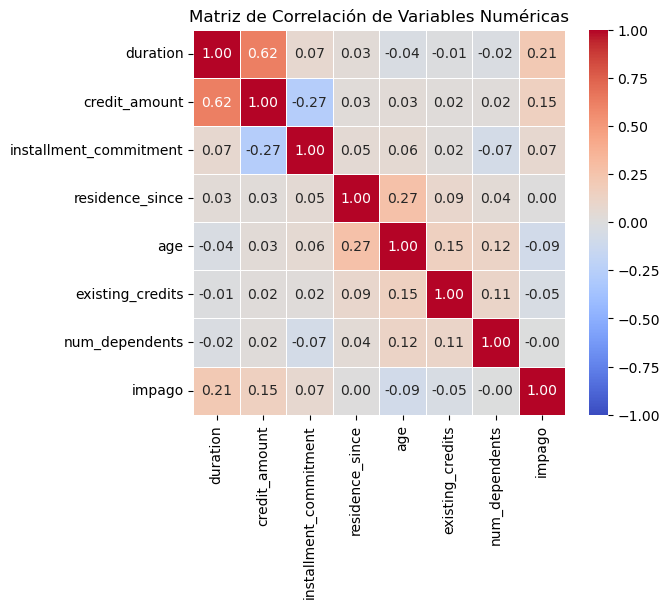

In [7]:
print("--- ESTADÍSTICAS CUANTITATIVAS SEGMENTADAS POR IMPAGO ---")
estadisticas_segmentadas = tmp.groupby("impago")[["credit_amount", "duration"]].agg(["mean", "median", "std", lambda x: np.percentile(x, 75), lambda x: np.percentile(x, 90)])

estadisticas_segmentadas.columns = [
    'Monto_Media', 'Monto_Mediana', 'Monto_DesvEst', 'Monto_P75', 'Monto_P90',
    'Plazo_Media', 'Plazo_Mediana', 'Plazo_DesvEst', 'Plazo_P75', 'Plazo_P90'
]
print(estadisticas_segmentadas.T.round(2)) 
columnas_numericas = tmp.select_dtypes(include=["int64", "float64"]).columns
matriz_corr = tmp[columnas_numericas].corr()

plt.figure(figsize=(6, 5))
sb.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de Variables Numéricas")
plt.show()

In [9]:
print(X["personal_status"].value_counts())

personal_status
male single           548
female div/dep/mar    310
male mar/wid           92
male div/sep           50
Name: count, dtype: int64


In [10]:
print("--- AUDITORÍA DE INTERSECCIONALIDAD (GÉNERO + EDAD) ---")
interseccional = tmp.groupby(['personal_status', 'rango_edad'], observed=False)['impago'].mean() * 100
print(interseccional.round(2))

--- AUDITORÍA DE INTERSECCIONALIDAD (GÉNERO + EDAD) ---
personal_status     rango_edad             
female div/dep/mar  <25 (Jóvenes)              44.76
                    25-34 (Adultos Jóvenes)    38.46
                    35-49 (Madurez)            18.87
                    50-64 (Pre-retiro)         20.00
                    >=65 (Retiro)              20.00
male div/sep        <25 (Jóvenes)               0.00
                    25-34 (Adultos Jóvenes)    50.00
                    35-49 (Madurez)            35.00
                    50-64 (Pre-retiro)         33.33
                    >=65 (Retiro)                NaN
male mar/wid        <25 (Jóvenes)              40.74
                    25-34 (Adultos Jóvenes)    21.74
                    35-49 (Madurez)            17.65
                    50-64 (Pre-retiro)         50.00
                    >=65 (Retiro)                NaN
male single         <25 (Jóvenes)              39.29
                    25-34 (Adultos Jóvenes)    24.41

In [11]:
conteo_edad_genero = tmp.groupby(['personal_status', 'rango_edad'], observed=False)['impago'].value_counts()
print(conteo_edad_genero)

personal_status     rango_edad               impago
female div/dep/mar  <25 (Jóvenes)            0          58
                                             1          47
                    25-34 (Adultos Jóvenes)  0          72
                                             1          45
                    35-49 (Madurez)          0          43
                                             1          10
                    50-64 (Pre-retiro)       0          24
                                             1           6
                    >=65 (Retiro)            0           4
                                             1           1
male div/sep        <25 (Jóvenes)            0           2
                                             1           0
                    25-34 (Adultos Jóvenes)  0          11
                                             1          11
                    35-49 (Madurez)          0          13
                                             1           7
    